# 1. Simulação dos dados de produção

> **Os dados deste projeto são SIMULADOS.** Foram gerados a partir de parâmetros de crescimento publicados na literatura científica, com variação aleatória para parecerem dados reais. Não são registos de nenhuma exploração.

Neste notebook:
1. Apresentamos os parâmetros das duas espécies e as suas referências.
2. Definimos a temperatura da água ao longo do ciclo.
3. Simulamos, dia a dia, um ciclo de engorda em jaula para a **dourada** (*Sparus aurata*) e para o **robalo** (*Dicentrarchus labrax*).
4. Transformamos a simulação em **registos de exploração** (biometrias de 14 em 14 dias), no mesmo formato que teriam dados reais, e guardamo-los em `data/raw/`.

In [1]:
import sys
sys.path.append("..")   # para o Python encontrar a pasta src/

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.growth import (PARAMETROS, PESO_INICIAL_G, CV_CRESCIMENTO_INDIVIDUAL,
                        perfil_temperatura, simular_ciclo, registos_de_exploracao,
                        dias_ate_peso, crescimento_diario, peso_critico)

sns.set_theme(style="whitegrid", context="notebook")
CORES = {"dourada": "#c9971c", "robalo": "#3f6ea6"}   # uma cor fixa para cada espécie
NOMES = {"dourada": "Dourada (Sparus aurata)", "robalo": "Robalo (Dicentrarchus labrax)"}

## 1.1 Parâmetros e referências

O crescimento é calculado com o **coeficiente de crescimento térmico (TGC)**. O peixe cresce em função da temperatura **acumulada** acima de 12 °C (temperatura efetiva): abaixo de 12 °C a dourada não come nem cresce (Mayer et al., 2008). Em cada dia:

$$W^{1/3} \leftarrow W^{1/3} + TGC_{1/3} \cdot (T - 12) \qquad \text{(peixes abaixo do peso crítico)}$$

$$W^{2/3} \leftarrow W^{2/3} + TGC_{2/3} \cdot (T - 12) \qquad \text{(peixes acima do peso crítico)}$$

- $W$ = peso do peixe (g); $T$ = temperatura da água (°C)
- o **peso crítico**, $(TGC_{2/3} / TGC_{1/3})^3 / 8$, é o peso em que as duas fases crescem ao mesmo ritmo (cerca de **117 g** na dourada)
- estes valores foram ajustados por Mayer et al. (2012) a **20 lotes de dourada em jaulas comerciais** (Valência, Espanha) e validados com mais 6 lotes

| Parâmetro | Dourada | Robalo | Referência |
|---|---|---|---|
| TGC | 0,001646 (fase $W^{1/3}$) · 0,016095 (fase $W^{2/3}$) | 0,00129 (só fase $W^{1/3}$) | Mayer et al. (2012); robalo: **calibração**, ver 1.5 |
| Temperatura base | 12 °C | 12 °C | Mayer et al. (2008); robalo: **pressuposto** |
| Sobrevivência no ciclo | 80 % | 85 % | Muniesa et al. (2020) |
| Duração de referência do ciclo | 14–16 meses | 16–18 meses | Cardia & Lovatelli (2007) |
| Peso dos juvenis à entrada | 2–4 g (usamos 3 g) | 2–4 g (usamos 3 g) | Cardia & Lovatelli (2007) |
| FCR médio | 2,1 | 2,2 | Kallitsis & Avramidis (2025) |
| Variação individual do crescimento | CV = 15 % | CV = 15 % | **Pressuposto** (sem referência) |
| Temperatura da água | 15–23 °C (curva sazonal) | igual | **Pressuposto** (ilustrativo) |

**Porquê este modelo?** Até outubro de 2026 o projeto usava $dW/dt = 0{,}024 \cdot W^{0,514} \cdot e^{0,060 \cdot T}$. Essa equação é de **Lupatsch, Kissil & Sklan (2003)** (por engano estava atribuída a Hernández et al., 2003). Mayer et al. (2008) aplicaram-na a jaulas comerciais e o peso final ficava errado em 16,6 %, contra cerca de 11 % dos modelos com temperatura efetiva. O TGC tem ainda uma vantagem prática: é um número que as explorações conseguem calcular com as suas próprias pesagens.

**Limites de validade:** os lotes de Mayer et al. começaram com 6–44 g, por isso abaixo de 6 g o modelo é uma extrapolação. O modelo não tem temperatura ótima; como o ótimo do robalo é de cerca de 26 °C (Person-Le Ruyet et al., 2004), só o usamos até 25 °C.

In [2]:
pd.DataFrame(PARAMETROS).T

,nome_cientifico,tgc_1_3,tgc_2_3,temperatura_base,sobrevivencia_ciclo,duracao_ciclo_dias,fcr
dourada,Sparus aurata,0.001646,0.016095,12.0,0.8,456,2.1
robalo,Dicentrarchus labrax,0.00129,None,12.0,0.85,517,2.2


In [3]:
# Exemplo: quanto cresce num dia um peixe de 100 g a 20 °C?
for especie in ["dourada", "robalo"]:
    g = float(crescimento_diario(100, 20, especie))
    print(f"{especie}: {g:.2f} g/dia  (= {g / 100 * 100:.2f} % do peso por dia)")
print(f"Peso crítico da dourada: {peso_critico(PARAMETROS['dourada']):.0f} g")

dourada: 0.85 g/dia  (= 0.85 % do peso por dia)
robalo: 0.67 g/dia  (= 0.67 % do peso por dia)
Peso crítico da dourada: 117 g


## 1.2 Temperatura da água

Os peixes entram na jaula a **1 de abril** (os ciclos começam normalmente na primavera; Cardia & Lovatelli, 2007). Usamos uma curva sazonal simples: mínimo de 15 °C em meados de fevereiro e máximo de 23 °C em meados de agosto. É um **pressuposto ilustrativo**, que pode ser trocado por dados reais de uma sonda de temperatura.

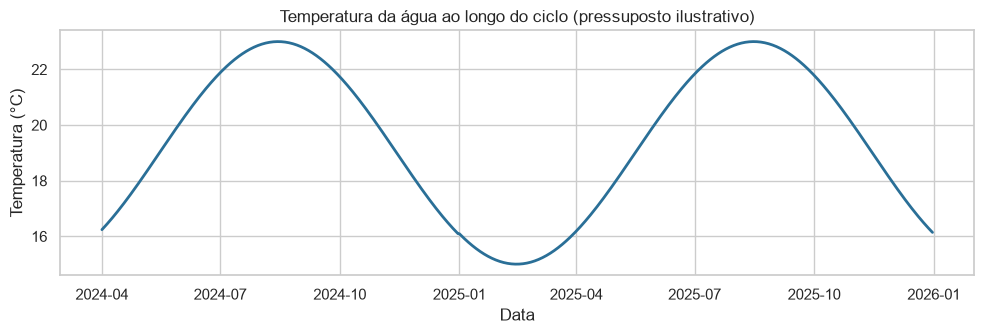

In [4]:
N_DIAS = 640   # cerca de 21 meses
datas, temperatura = perfil_temperatura(N_DIAS, data_inicio="2024-04-01")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(datas, temperatura, color="#2a6f97", linewidth=2)
ax.set_title("Temperatura da água ao longo do ciclo (pressuposto ilustrativo)")
ax.set_xlabel("Data")
ax.set_ylabel("Temperatura (°C)")
plt.tight_layout()
plt.savefig("../figures/01_temperatura.png", dpi=150)
plt.show()

## 1.3 Simulação de um ciclo de engorda

Para cada espécie simulamos uma jaula com **5 000 peixes**, dia a dia:

1. **Mortalidade:** cada peixe tem uma pequena probabilidade de morrer em cada dia, calculada para que, no fim da duração de referência do ciclo, sobrevivam 80 % (dourada) ou 85 % (robalo).
2. **Crescimento:** cada peixe cresce segundo o modelo TGC acima. Para haver **variação individual**, cada peixe tem um "ritmo" próprio (uns crescem mais depressa, outros mais devagar).
3. **Ração:** a ração do dia é o ganho de biomassa multiplicado pelo FCR, com uma pequena variação de dia para dia.

Usamos uma **semente aleatória** (`semente=42`) para que os resultados sejam sempre iguais quando se volta a correr o notebook.

In [5]:
simulacoes = {}
for especie in ["dourada", "robalo"]:
    simulacoes[especie] = simular_ciclo(especie, n_dias=N_DIAS, n_peixes=5000,
                                        temperatura=temperatura, semente=42)

simulacoes["dourada"].head()

,especie,dia,data,temperatura_c,n_peixes,peso_medio_g,peso_dp_g,biomassa_kg,racao_kg,mortos
0,dourada,0,2024-04-01,16.24,4998,3.043629,0.006592,15.212055,0.410393,2
1,dourada,1,2024-04-02,16.29,4994,3.088218,0.013390,15.422560,0.479211,4
2,dourada,2,2024-04-03,16.34,4991,3.133793,0.020401,15.640762,0.528932,3
3,dourada,3,2024-04-04,16.39,4987,3.180384,0.027637,15.860575,0.544014,4
4,dourada,4,2024-04-05,16.45,4982,3.228003,0.035086,16.081911,0.514247,5


In [6]:
# Resumo de cada simulação
resumo = []
for especie, sim in simulacoes.items():
    fim = sim.iloc[-1]
    ganho_biomassa = fim["biomassa_kg"] - 5000 * PESO_INICIAL_G / 1000
    resumo.append({
        "espécie": especie,
        "dias até 400 g": dias_ate_peso(sim, 400),
        "meses até 400 g": round(dias_ate_peso(sim, 400) / 30.4, 1),
        f"peso médio ao dia {N_DIAS} (g)": round(fim["peso_medio_g"]),
        "sobrevivência ao dia 400 (%)": round(sim.loc[400, "n_peixes"] / 5000 * 100, 1),
        "ração total (kg)": round(sim["racao_kg"].sum()),
        "FCR do ciclo": round(sim["racao_kg"].sum() / ganho_biomassa, 2),
    })
pd.DataFrame(resumo).set_index("espécie")

,dias até 400 g,meses até 400 g,peso médio ao dia 640 (g),sobrevivência ao dia 400 (%),ração total (kg),FCR do ciclo
espécie,,,,,,
dourada,528,17.4,557,82.3,4760,2.34
robalo,590,19.4,462,88.0,4360,2.33


### Curvas de crescimento

A linha é o peso médio da jaula e a zona sombreada mostra a variação entre peixes (± 1 desvio-padrão). A linha tracejada marca o tamanho comercial de 400 g.

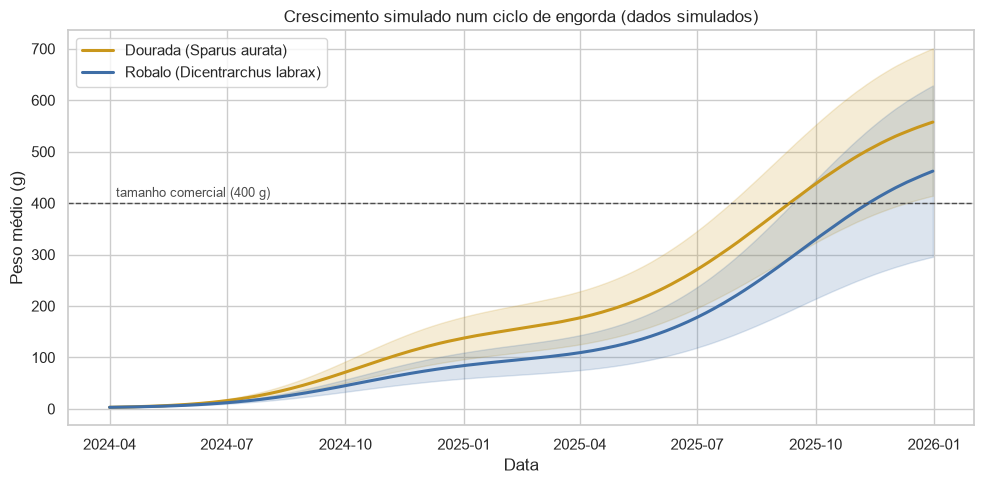

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
for especie, sim in simulacoes.items():
    ax.plot(sim["data"], sim["peso_medio_g"], color=CORES[especie], linewidth=2.2, label=NOMES[especie])
    ax.fill_between(sim["data"], sim["peso_medio_g"] - sim["peso_dp_g"],
                    sim["peso_medio_g"] + sim["peso_dp_g"], color=CORES[especie], alpha=0.18)
ax.axhline(400, color="0.3", linestyle="--", linewidth=1)
ax.text(simulacoes["dourada"]["data"].iloc[5], 412, "tamanho comercial (400 g)", color="0.3", fontsize=9)
ax.set_title("Crescimento simulado num ciclo de engorda (dados simulados)")
ax.set_xlabel("Data")
ax.set_ylabel("Peso médio (g)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("../figures/01_crescimento_simulado.png", dpi=150)
plt.show()

### Variação entre peixes

Mesmo na mesma jaula, os peixes não têm todos o mesmo tamanho. O gráfico mostra o peso médio e o desvio-padrão das duas espécies no dia em que a dourada atinge, em média, os 400 g.

dourada ao dia 528: média 400 g, desvio-padrão 106 g, CV 26%
robalo ao dia 528: média 292 g, desvio-padrão 102 g, CV 35%


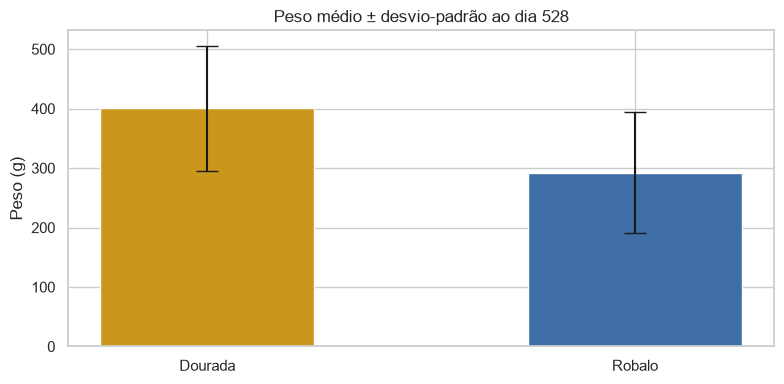

In [8]:
dia_alvo = dias_ate_peso(simulacoes["dourada"], 400)
fig, ax = plt.subplots(figsize=(8, 4))
for especie in ["dourada", "robalo"]:
    sim = simulacoes[especie]
    media, dp = sim.loc[dia_alvo, "peso_medio_g"], sim.loc[dia_alvo, "peso_dp_g"]
    print(f"{especie} ao dia {dia_alvo}: média {media:.0f} g, desvio-padrão {dp:.0f} g, CV {dp / media:.0%}")
ax.bar(["Dourada", "Robalo"],
       [simulacoes[e].loc[dia_alvo, "peso_medio_g"] for e in ["dourada", "robalo"]],
       yerr=[simulacoes[e].loc[dia_alvo, "peso_dp_g"] for e in ["dourada", "robalo"]],
       color=[CORES["dourada"], CORES["robalo"]], capsize=8, width=0.5)
ax.set_title(f"Peso médio ± desvio-padrão ao dia {dia_alvo}")
ax.set_ylabel("Peso (g)")
plt.tight_layout()
plt.show()

### Sobrevivência

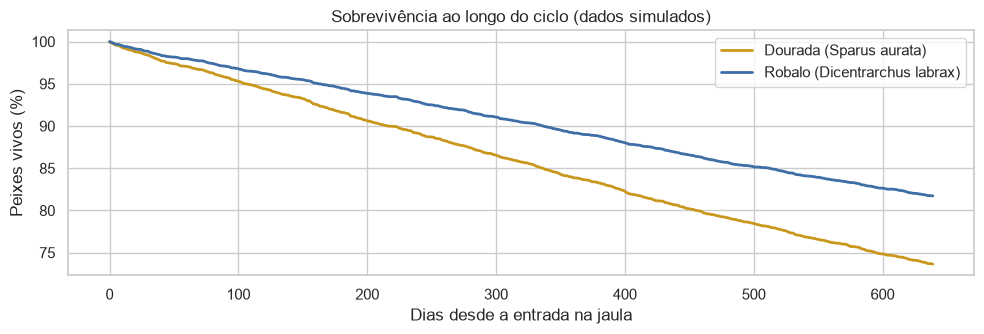

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for especie, sim in simulacoes.items():
    ax.plot(sim["dia"], sim["n_peixes"] / 5000 * 100, color=CORES[especie], linewidth=2, label=NOMES[especie])
ax.set_title("Sobrevivência ao longo do ciclo (dados simulados)")
ax.set_xlabel("Dias desde a entrada na jaula")
ax.set_ylabel("Peixes vivos (%)")
ax.legend()
plt.tight_layout()
plt.show()

## 1.4 Registos de exploração

Numa exploração real não se pesam todos os peixes todos os dias. Faz-se uma **biometria** (pesagem de uma amostra) de tempos a tempos. Para imitar isso:
- de **14 em 14 dias** estimamos o peso médio a partir de uma amostra de **50 peixes** (por isso há erro de amostragem);
- somamos a ração dada entre biometrias;
- registamos a temperatura média do período e o número de peixes vivos.

O resultado tem exatamente as colunas que teriam dados reais: `dia, peso_medio_g, temperatura_c, racao_kg, n_peixes`. Para usar dados reais no futuro basta substituir este ficheiro.

In [10]:
registos = pd.concat([registos_de_exploracao(simulacoes[e], intervalo_dias=14, n_amostra=50)
                      for e in ["dourada", "robalo"]], ignore_index=True)
registos.to_csv("../data/raw/registos_simulados.csv", index=False)
print(len(registos), "registos guardados em data/raw/registos_simulados.csv")
registos.head(8)

92 registos guardados em data/raw/registos_simulados.csv


,especie,dia,data,peso_medio_g,temperatura_c,racao_kg,n_peixes
0,dourada,0,2024-04-01,3.0,16.2,0.0,4998
1,dourada,14,2024-04-15,3.8,16.6,7.6,4955
2,dourada,28,2024-04-29,4.8,17.4,9.8,4923
3,dourada,42,2024-05-13,6.0,18.3,13.6,4884
4,dourada,56,2024-05-27,8.1,19.3,18.6,4855
5,dourada,70,2024-06-10,10.7,20.2,25.0,4834
6,dourada,84,2024-06-24,13.8,21.1,34.3,4802
7,dourada,98,2024-07-08,18.7,21.9,41.7,4768


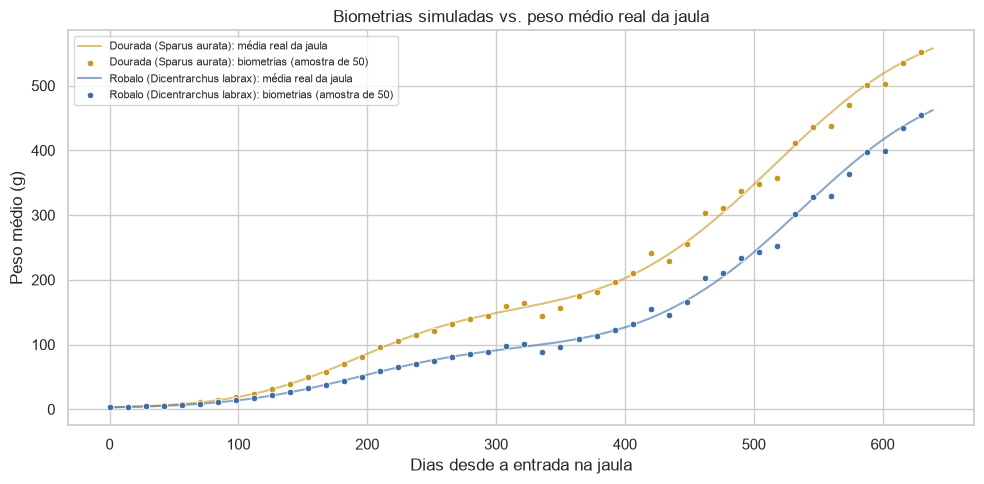

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
for especie, sim in simulacoes.items():
    reg = registos[registos["especie"] == especie]
    ax.plot(sim["dia"], sim["peso_medio_g"], color=CORES[especie], linewidth=1.5, alpha=0.6,
            label=f"{NOMES[especie]}: média real da jaula")
    ax.scatter(reg["dia"], reg["peso_medio_g"], color=CORES[especie], s=22, edgecolor="white", linewidth=0.6,
               zorder=3, label=f"{NOMES[especie]}: biometrias (amostra de 50)")
ax.set_title("Biometrias simuladas vs. peso médio real da jaula")
ax.set_xlabel("Dias desde a entrada na jaula")
ax.set_ylabel("Peso médio (g)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [12]:
# Validação independente: a FAO (2009) indica ≈ 16 meses em jaula para juvenis de 5 g até 350–400 g
sim_5g = simular_ciclo("dourada", n_dias=N_DIAS, n_peixes=5000, temperatura=temperatura,
                       peso_inicial_g=5.0, semente=42)
dias_5g = dias_ate_peso(sim_5g, 400)
print(f"Dourada de 5 g até 400 g: {dias_5g} dias (≈ {dias_5g / 30.4:.1f} meses)")

Dourada de 5 g até 400 g: 513 dias (≈ 16.9 meses)


## 1.5 Validação e conclusões

**A simulação é coerente com a literatura?**

| | Simulação | Literatura |
|---|---|---|
| Dourada de 3 g até 400 g | 528 dias (≈ 17,4 meses) | 14–16 meses (Cardia & Lovatelli, 2007) |
| Dourada de 5 g até 400 g | 513 dias (≈ 16,9 meses) | ≈ 16 meses (FAO, 2009) |
| Robalo de 3 g até 400 g | 590 dias (≈ 19,4 meses) | 16–18 meses (Cardia & Lovatelli, 2007) |

Com o modelo de Mayer et al. (2012) a dourada demora um pouco mais do que os 14–16 meses de Cardia & Lovatelli (2007), mas fica perto dos ≈ 16 meses da FAO (2009) para juvenis de 5 g. A diferença vem sobretudo da **nossa curva de temperatura** (pressuposto, média de 19 °C): numa zona mais quente o ciclo encurta. Por exemplo, os lotes de Mayer et al. cresceram com temperaturas entre 13 e 26,5 °C.

**Calibração do robalo:** não encontrámos um TGC do robalo medido em jaulas comerciais. Por isso escolhemos o TGC do robalo (0,00129) para que demore **mais 13 %** do que a dourada a chegar aos 400 g, que é a diferença entre os ciclos de referência das duas espécies (14–16 vs. 16–18 meses; Cardia & Lovatelli, 2007). Assim a comparação entre espécies segue a literatura, mesmo que a duração absoluta dependa da curva de temperatura. Este valor **não é publicado** e deve ser substituído pelo TGC de uma exploração quando houver dados.

**O que os dados mostram:**
- A **dourada cresce mais depressa** do que o robalo: chega aos 400 g cerca de 2 meses antes.
- O crescimento **para quase por completo no inverno** e acelera no verão: com o TGC, só conta a temperatura acima de 12 °C, por isso um mês a 15 °C vale muito menos do que um mês a 22 °C.
- Há bastante **variação entre peixes** (coeficiente de variação de cerca de 25–35 % no peso), resultado do pressuposto de 15 % de variação no ritmo de crescimento individual.
- O **FCR do ciclo (≈ 2,3)** é mais alto do que o FCR de base (2,1 e 2,2), porque parte da ração foi comida por peixes que morreram antes da despesca. É a diferença entre o FCR biológico e o FCR **económico** usado nas explorações.
- A mortalidade diária foi calculada para a duração de referência do ciclo (15 e 17 meses). Como o ciclo simulado é mais longo, a sobrevivência no dia da despesca fica um pouco abaixo dos 80 % e 85 %.

**Ficheiro criado:** `data/raw/registos_simulados.csv`, com 92 biometrias (46 por espécie), que vamos usar nos próximos notebooks.

**Limitações:** a curva de temperatura e a variação individual são pressupostos; abaixo de 6 g o modelo é uma extrapolação; o modelo não inclui temperaturas acima de 25 °C, doenças pontuais, nem triagens (separação por tamanhos).